In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# index_col/parse_dates turn the "valid" column back into a real timestamp index
df = pd.read_csv("../data/processed/unv_model_ready.csv", index_col="valid", parse_dates=True)

CLASS_NAMES = ["Clear", "Changing", "Precipitation"]
FEATURES = [c for c in df.columns if c != "label"]

print(df.shape)
print(df.index.min(), "->", df.index.max())
print("Features:", FEATURES)

(89844, 17)
2015-01-02 00:00:00 -> 2025-12-31 20:00:00
Features: ['temp_c', 'rh_pct', 'dew_spread_c', 'dp_1h', 'dp_3h', 'dp_6h', 'dtemp_3h', 'drh_3h', 'dp_12h', 'dp_24h', 'dp_accel', 'dspread_3h', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [2]:
BUFFER = pd.Timedelta(hours=12)   # gap so labels near a boundary can't peek into the next set

TRAIN_END = pd.Timestamp("2022-01-01")   # train:      before 2022
VAL_END   = pd.Timestamp("2024-01-01")   # validation: 2022-2023, test: 2024 onward

train = df[df.index < TRAIN_END - BUFFER]
val   = df[(df.index >= TRAIN_END) & (df.index < VAL_END - BUFFER)]
test  = df[df.index >= VAL_END]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    share = part["label"].value_counts(normalize=True).sort_index() * 100
    mix = "  ".join(f"{CLASS_NAMES[i]} {share.get(i, 0):.1f}%" for i in range(3))
    print(f"{name:10s} {len(part):6d} rows  {part.index.min().date()} to {part.index.max().date()}   {mix}")

train       56072 rows  2015-01-02 to 2021-12-31   Clear 78.1%  Changing 2.8%  Precipitation 19.1%
validation  17207 rows  2022-01-01 to 2023-12-31   Clear 79.3%  Changing 2.8%  Precipitation 17.9%
test        16541 rows  2024-01-01 to 2025-12-31   Clear 78.3%  Changing 2.8%  Precipitation 18.9%


In [3]:
# Class mix per year. If a year looks very different, that's worth knowing before we train.
per_year = pd.crosstab(df.index.year, df["label"], normalize="index").round(3) * 100
per_year.columns = CLASS_NAMES
per_year

,Clear,Changing,Precipitation
row_0,,,
2015,79.1,3.3,17.6
2016,79.3,3.3,17.4
2017,78.0,2.6,19.4
2018,76.0,2.2,21.9
2019,78.7,2.8,18.5
2020,78.2,2.6,19.2
2021,77.3,2.6,20.1
2022,78.9,2.9,18.2
2023,79.7,2.7,17.6


## Preparing the data for a model and setting baselines

**X and y:** `X` holds the inputs (the 12 features), `y` holds the answer key (Clear / Changing / Precipitation).
The model sees `X` and tries to predict `y`.

**Scaling:** features live on very different scales (humidity is 0-100, a 1-hour pressure change is about ±0.5).
We rescale them so no feature dominates just because its numbers are bigger. The scaling numbers are
learned from the TRAINING set only; using validation or test data here would leak information about the "future."

**Baselines:** before building a neural network we measure simple models. A neural network is only worth
the ESP32 memory if it clearly beats them.

In [4]:
from sklearn.preprocessing import StandardScaler

# Split each time period into inputs (X) and answers (y)
X_train, y_train = train[FEATURES], train["label"]
X_val,   y_val   = val[FEATURES],   val["label"]
X_test,  y_test  = test[FEATURES],  test["label"]

# Scale these 12 features. The sin/cos time features are already between -1 and 1, so we leave them alone.
SCALE_COLS = ["temp_c", "rh_pct", "dew_spread_c", "dp_1h", "dp_3h", "dp_6h", "dtemp_3h", "drh_3h",
              "dp_12h", "dp_24h", "dp_accel", "dspread_3h"]

# StandardScaler turns each value into: (value - mean) / standard deviation
# After that, every feature has mean ~0 and spread ~1.
scaler = StandardScaler()
scaler.fit(X_train[SCALE_COLS])          # LEARN the mean and std from TRAINING data only

def scale(X):
    X = X.copy()
    X[SCALE_COLS] = scaler.transform(X[SCALE_COLS])   # APPLY those same numbers; never re-learn them
    return X

X_train_s, X_val_s, X_test_s = scale(X_train), scale(X_val), scale(X_test)

# Check: training should be ~0 mean / ~1 std; validation will be CLOSE but not exact. That is correct.
print("train mean:", X_train_s[SCALE_COLS].mean().round(2).tolist())
print("train std: ", X_train_s[SCALE_COLS].std().round(2).tolist())
print("val mean:  ", X_val_s[SCALE_COLS].mean().round(2).tolist())

train mean: [0.0, 0.0, -0.0, 0.0, -0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0, 0.0]
train std:  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
val mean:   [0.04, -0.1, 0.12, 0.0, 0.0, 0.01, -0.02, 0.01, 0.01, 0.01, -0.0, -0.02]


In [5]:
import json
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
scaler_info = {
    "feature_order": FEATURES,                       # the model expects inputs in exactly this order
    "scaled_columns": SCALE_COLS,
    "mean":  scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),                 # "scale" is the standard deviation
}
with open("../models/scaler.json", "w") as f:
    json.dump(scaler_info, f, indent=2)
print("Saved models/scaler.json")

Saved models/scaler.json


In [6]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

def evaluate(name, y_true, y_pred):
    """Print the scores we will use to compare every model in this project."""
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}   "
          f"Macro-F1: {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]),
                      index=[f"true {n}" for n in CLASS_NAMES],
                      columns=[f"pred {n}" for n in CLASS_NAMES])
    print(cm, "\n")

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Baseline 1: always predict the most common class (Clear). The "do nothing smart" floor.
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
evaluate("Always predict Clear", y_val, dummy.predict(X_val_s))

# Baseline 2: logistic regression, a simple classical model that draws straight-line boundaries.
logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
evaluate("Logistic regression", y_val, logreg.predict(X_val_s))

# Baseline 3: same model, but mistakes on rare classes cost MORE during training
# ("balanced" weights each class inversely to how common it is).
logreg_bal = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_s, y_train)
evaluate("Logistic regression (balanced)", y_val, logreg_bal.predict(X_val_s))

===== Always predict Clear =====
Accuracy: 0.793   Macro-F1: 0.295
               precision    recall  f1-score   support

        Clear      0.793     1.000     0.885     13646
     Changing      0.000     0.000     0.000       483
Precipitation      0.000     0.000     0.000      3078

     accuracy                          0.793     17207
    macro avg      0.264     0.333     0.295     17207
 weighted avg      0.629     0.793     0.702     17207

                    pred Clear  pred Changing  pred Precipitation
true Clear               13646              0                   0
true Changing              483              0                   0
true Precipitation        3078              0                   0 

===== Logistic regression =====
Accuracy: 0.828   Macro-F1: 0.486
               precision    recall  f1-score   support

        Clear      0.844     0.972     0.904     13646
     Changing      0.418     0.079     0.132       483
Precipitation      0.675     0.307     0.422   

In [8]:
from sklearn.metrics import precision_recall_fscore_support

scores = []
def add_score(name, y_true, y_pred):
    """Add one row of key numbers to the comparison table and return the whole table."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    scores.append({
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "macro_F1": round(f.mean(), 3),
        "recall_Clear": round(r[0], 3), "recall_Changing": round(r[1], 3), "recall_Precip": round(r[2], 3),
        "prec_Changing": round(p[1], 3), "prec_Precip": round(p[2], 3),
    })
    return pd.DataFrame(scores)

add_score("Always Clear", y_val, dummy.predict(X_val_s))
add_score("LogReg", y_val, logreg.predict(X_val_s))
add_score("LogReg balanced", y_val, logreg_bal.predict(X_val_s))

,model,accuracy,macro_F1,recall_Clear,recall_Changing,recall_Precip,prec_Changing,prec_Precip
0,Always Clear,0.793,0.295,1.000,0.000,0.000,0.000,0.000
1,LogReg,0.828,0.486,0.972,0.079,0.307,0.418,0.675
2,LogReg balanced,0.676,0.501,0.701,0.760,0.553,0.146,0.398


In [9]:
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(42)    # makes results repeatable; training starts from random weights

# TensorFlow wants plain NumPy arrays of 32-bit numbers (smaller and faster than Pandas tables)
Xtr = X_train_s.to_numpy().astype("float32")
Xva = X_val_s.to_numpy().astype("float32")
ytr = y_train.to_numpy()          # integers 0, 1, 2
yva = y_val.to_numpy()

# Rare classes get larger weights, so a mistake on a Changing hour counts more than on a Clear hour.
# This is the neural-network version of class_weight="balanced" from the logistic regression.
cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=ytr)
print(dict(zip(CLASS_NAMES, cw.round(2))))

w_tr = cw[ytr]     # one weight per hour, depending on that hour's true class
w_va = cw[yva]     # applied to validation too, so training and validation loss are comparable

{'Clear': np.float64(0.43), 'Changing': np.float64(12.03), 'Precipitation': np.float64(1.74)}


In [10]:
model = keras.Sequential([
    keras.layers.Input(shape=(len(FEATURES),)),        # 12 numbers in
    keras.layers.Dense(16, activation="relu"),         # layer 1: 16 neurons
    keras.layers.Dense(8,  activation="relu"),         # layer 2: 8 neurons
    keras.layers.Dense(3,  activation="softmax"),      # output: 3 probabilities (Clear, Changing, Precipitation)
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 435 (1.70 KB)

 Trainable params: 435 (1.70 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",           # watch the validation loss
    patience=10,                  # stop if it hasn't improved for 10 epochs
    restore_best_weights=True,    # then go back to the best epoch
)

history = model.fit(
    Xtr, ytr,
    sample_weight=w_tr,                       # training weights per hour
    validation_data=(Xva, yva, w_va),         # validation data + its weights
    epochs=100,                               # the maximum; early stopping will usually stop sooner
    batch_size=256,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/100
220/220 - 1s - 3ms/step - loss: 1.0306 - val_loss: 0.8226
Epoch 2/100
220/220 - 0s - 1ms/step - loss: 0.8259 - val_loss: 0.7535
Epoch 3/100
220/220 - 0s - 1ms/step - loss: 0.7920 - val_loss: 0.7346
Epoch 4/100
220/220 - 0s - 1ms/step - loss: 0.7765 - val_loss: 0.7235
Epoch 5/100
220/220 - 0s - 1ms/step - loss: 0.7669 - val_loss: 0.7167
Epoch 6/100
220/220 - 0s - 1ms/step - loss: 0.7609 - val_loss: 0.7131
Epoch 7/100
220/220 - 0s - 1ms/step - loss: 0.7560 - val_loss: 0.7099
Epoch 8/100
220/220 - 0s - 1ms/step - loss: 0.7524 - val_loss: 0.7075
Epoch 9/100
220/220 - 0s - 1ms/step - loss: 0.7498 - val_loss: 0.7061
Epoch 10/100
220/220 - 0s - 2ms/step - loss: 0.7469 - val_loss: 0.7043
Epoch 11/100
220/220 - 0s - 2ms/step - loss: 0.7447 - val_loss: 0.7040
Epoch 12/100
220/220 - 0s - 1ms/step - loss: 0.7427 - val_loss: 0.7025
Epoch 13/100
220/220 - 0s - 1ms/step - loss: 0.7406 - val_loss: 0.7013
Epoch 14/100
220/220 - 0s - 1ms/step - loss: 0.7391 - val_loss: 0.7009
Epoch 15/100
22

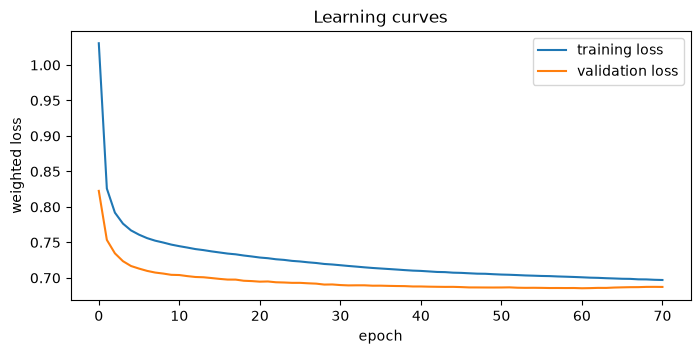

In [12]:
plt.figure(figsize=(8, 3.5))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("weighted loss"); plt.legend(); plt.title("Learning curves")
plt.show()

In [13]:
probs = model.predict(Xva, verbose=0)     # shape (17214, 3): a probability for each class, per hour
pred  = probs.argmax(axis=1)              # pick the most likely class

evaluate("Neural network 12-16-8-3", yva, pred)
add_score("NN 12-16-8-3", yva, pred)

===== Neural network 12-16-8-3 =====
Accuracy: 0.703   Macro-F1: 0.532
               precision    recall  f1-score   support

        Clear      0.934     0.712     0.808     13646
     Changing      0.152     0.731     0.251       483
Precipitation      0.452     0.657     0.536      3078

     accuracy                          0.703     17207
    macro avg      0.513     0.700     0.532     17207
 weighted avg      0.826     0.703     0.744     17207

                    pred Clear  pred Changing  pred Precipitation
true Clear                9716           1567                2363
true Changing               43            353                  87
true Precipitation         647            408                2023 



,model,accuracy,macro_F1,recall_Clear,recall_Changing,recall_Precip,prec_Changing,prec_Precip
0,Always Clear,0.793,0.295,1.000,0.000,0.000,0.000,0.000
1,LogReg,0.828,0.486,0.972,0.079,0.307,0.418,0.675
2,LogReg balanced,0.676,0.501,0.701,0.760,0.553,0.146,0.398
3,NN 12-16-8-3,0.703,0.532,0.712,0.731,0.657,0.152,0.452


## Experiment: is the network's advantage real, and does size matter?

Training starts from random weights, so every run differs a little. We train each architecture with 3
different random seeds and report the average and spread. If a difference between two architectures is
smaller than the spread between seeds, it is noise, not a real improvement.

In [14]:
def train_mlp(hidden=(16, 8), features=FEATURES, seed=42, epochs=150):
    """Train one small network and return (model, validation predictions).
    hidden   : neurons per hidden layer, e.g. (16, 8) = two hidden layers
    features : which input columns to use (lets us test removing some later)
    seed     : controls the random starting weights"""
    keras.utils.set_random_seed(seed)
    cols = [FEATURES.index(f) for f in features]      # pick those columns out of the scaled arrays
    layers = [keras.layers.Input(shape=(len(cols),))]
    layers += [keras.layers.Dense(n, activation="relu") for n in hidden]
    layers += [keras.layers.Dense(3, activation="softmax")]
    m = keras.Sequential(layers)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    m.fit(Xtr[:, cols], ytr, sample_weight=w_tr,
          validation_data=(Xva[:, cols], yva, w_va),
          epochs=epochs, batch_size=256, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                   restore_best_weights=True)])
    pred = m.predict(Xva[:, cols], verbose=0).argmax(axis=1)
    return m, pred

results = []
for hidden in [(4,), (8, 4), (16, 8), (32, 16), (64, 32)]:
    for seed in (1, 2, 3):
        m, pred = train_mlp(hidden=hidden, seed=seed)
        results.append({"architecture": str(hidden), "params": m.count_params(), "seed": seed,
                        "macro_F1": f1_score(yva, pred, average="macro"),
                        "recall_Precip": precision_recall_fscore_support(yva, pred, labels=[0, 1, 2], zero_division=0)[1][2]})

res = pd.DataFrame(results)
res.groupby(["architecture", "params"], sort=False)[["macro_F1", "recall_Precip"]].agg(["mean", "std"]).round(3)

macro_F1        recall_Precip       
                        mean    std          mean    std
architecture params                                     
(4,)         83        0.514  0.004         0.588  0.020
(8, 4)       187       0.517  0.002         0.598  0.022
(16, 8)      435       0.523  0.004         0.627  0.017
(32, 16)     1123      0.518  0.002         0.638  0.022
(64, 32)     3267      0.524  0.010         0.648  0.043

In [15]:
groups = {
    "all 12 features":            FEATURES,
    "no time (no clock needed)":  [f for f in FEATURES if not f.startswith(("hour", "month"))],
    "no humidity info":           [f for f in FEATURES if f not in ("rh_pct", "dew_spread_c", "drh_3h")],
    "no pressure trends":         [f for f in FEATURES if f not in ("dp_1h", "dp_3h", "dp_6h")],
    "no trends at all":           [f for f in FEATURES if f not in ("dp_1h", "dp_3h", "dp_6h", "dtemp_3h", "drh_3h")],
    "pressure trends only":       ["dp_1h", "dp_3h", "dp_6h"],
}

rows = []
for name, feats in groups.items():
    for seed in (1, 2, 3):
        m, pred = train_mlp(hidden=(16, 8), features=feats, seed=seed)
        p, r, f, _ = precision_recall_fscore_support(yva, pred, labels=[0, 1, 2], zero_division=0)
        rows.append({"inputs": name, "n_features": len(feats),
                     "macro_F1": f.mean(), "F1_Changing": f[1], "F1_Precip": f[2]})

abl = pd.DataFrame(rows)
abl.groupby(["inputs", "n_features"], sort=False).agg(["mean", "std"]).round(3)

macro_F1        F1_Changing         \
                                         mean    std        mean    std   
inputs                    n_features                                      
all 12 features           16            0.523  0.004       0.254  0.006   
no time (no clock needed) 12            0.510  0.007       0.253  0.004   
no humidity info          13            0.485  0.004       0.235  0.005   
no pressure trends        13            0.508  0.004       0.223  0.004   
no trends at all          11            0.503  0.001       0.214  0.001   
pressure trends only      3             0.414  0.004       0.194  0.003   

                                     F1_Precip         
                                          mean    std  
inputs                    n_features                   
all 12 features           16             0.514  0.007  
no time (no clock needed) 12             0.487  0.012  
no humidity info          13             0.439  0.007  
no pressure trends        13             0.513  0.002  
no trends at all          11             0.510  0.005  
pressure trends only      3              0.228  0.009

## What is the clock actually contributing?

Two checks: (1) does pressure have a daily cycle unrelated to weather (the atmospheric tide)? and
(2) how well does a model that only knows the hour and month (no sensors at all) do?

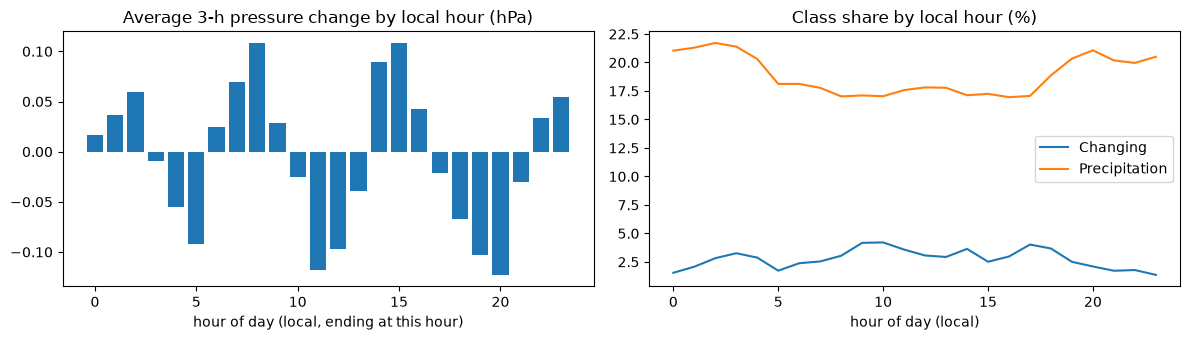

,macro_F1,F1_Changing,F1_Precip
mean,0.308,0.102,0.199
std,0.003,0.000,0.007


In [16]:
local = df.index.tz_localize("UTC").tz_convert("America/New_York")

# 1) Average 3-hour pressure change for each local hour of day, across 11 years.
#    If weather were the only thing moving pressure, these would all be close to 0.
tide = df.groupby(local.hour)["dp_3h"].mean()
by_hour = pd.crosstab(local.hour, df["label"], normalize="index") * 100
by_hour.columns = CLASS_NAMES

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(tide.index, tide.values)
ax[0].set_title("Average 3-h pressure change by local hour (hPa)")
ax[0].set_xlabel("hour of day (local, ending at this hour)")
by_hour[["Changing", "Precipitation"]].plot(ax=ax[1])
ax[1].set_title("Class share by local hour (%)"); ax[1].set_xlabel("hour of day (local)")
plt.tight_layout(); plt.show()

# 2) A model that sees ONLY the clock (hour + month), no sensors at all.
time_feats = ["hour_sin", "hour_cos", "month_sin", "month_cos"]
rows = []
for seed in (1, 2, 3):
    m, pred = train_mlp(hidden=(16, 8), features=time_feats, seed=seed)
    p, r, f, _ = precision_recall_fscore_support(yva, pred, labels=[0, 1, 2], zero_division=0)
    rows.append({"macro_F1": f.mean(), "F1_Changing": f[1], "F1_Precip": f[2]})
pd.DataFrame(rows).agg(["mean", "std"]).round(3)

In [17]:
from sklearn.metrics import average_precision_score

keras.utils.set_random_seed(42)
m_plain = keras.Sequential([
    keras.layers.Input(shape=(len(FEATURES),)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])
m_plain.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
m_plain.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=150, batch_size=256, verbose=0,   # NO sample_weight
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
p = m_plain.predict(Xva, verbose=0)          # now a roughly honest probability for each class

rows = []
for cls, name, cutoffs in [(2, "Precipitation", [0.15, 0.2, 0.3, 0.4, 0.5]),
                           (1, "Changing",      [0.03, 0.05, 0.08, 0.12, 0.2])]:
    is_cls = (yva == cls)
    print(f"{name}: base rate {is_cls.mean():.3f}, average precision {average_precision_score(is_cls, p[:, cls]):.3f}")
    for c in cutoffs:
        flagged = p[:, cls] >= c                       # raise an alert when probability is at least c
        tp = (flagged & is_cls).sum()                  # true positives: alerts that were right
        rows.append({"class": name, "cutoff": c, "alerts": int(flagged.sum()),
                     "precision": round(tp / max(flagged.sum(), 1), 3),
                     "recall": round(tp / is_cls.sum(), 3)})
pd.DataFrame(rows)

Precipitation: base rate 0.179, average precision 0.592
Changing: base rate 0.028, average precision 0.263


,class,cutoff,alerts,precision,recall
0,Precipitation,0.15,6548,0.383,0.815
1,Precipitation,0.20,5330,0.434,0.751
2,Precipitation,0.30,3622,0.527,0.620
3,Precipitation,0.40,2587,0.596,0.501
4,Precipitation,0.50,1803,0.667,0.391
5,Changing,0.03,3238,0.128,0.857
6,Changing,0.05,2206,0.164,0.749
7,Changing,0.08,1436,0.206,0.613
8,Changing,0.12,935,0.251,0.487
9,Changing,0.20,456,0.329,0.311


In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier

# --- 1) Calibration: group hours by predicted probability, compare to what really happened ---
for cls, name, edges in [(2, "Precipitation", [0, .1, .2, .3, .4, .5, .7, 1.0]),
                         (1, "Changing",      [0, .03, .06, .1, .15, .25, 1.0])]:
    tmp = pd.DataFrame({"predicted": p[:, cls], "actual": (yva == cls)})
    table = (tmp.groupby(pd.cut(tmp["predicted"], edges), observed=True)
                .agg(hours=("actual", "size"), mean_predicted=("predicted", "mean"), actual_rate=("actual", "mean"))
                .round(3))
    print(f"\n{name}: is mean_predicted close to actual_rate?")
    print(table)

# --- 2) A different model type on the same inputs, as a ceiling check ---
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4,
                                     early_stopping=False, random_state=0)
hgb.fit(X_train, y_train)               # trees don't need scaled inputs
ph = hgb.predict_proba(X_val)

print("\nAverage precision, same 12 inputs:")
for cls, name in [(2, "Precipitation"), (1, "Changing")]:
    print(f"  {name:14s} NN {average_precision_score(yva == cls, p[:, cls]):.3f}   "
          f"gradient boosting {average_precision_score(yva == cls, ph[:, cls]):.3f}")


Precipitation: is mean_predicted close to actual_rate?
            hours  mean_predicted  actual_rate
predicted                                     
(0.0, 0.1]   8924           0.037        0.040
(0.1, 0.2]   2953           0.144        0.139
(0.2, 0.3]   1708           0.246        0.237
(0.3, 0.4]   1035           0.347        0.353
(0.4, 0.5]    784           0.448        0.435
(0.5, 0.7]   1037           0.589        0.585
(0.7, 1.0]    766           0.820        0.777

Changing: is mean_predicted close to actual_rate?
              hours  mean_predicted  actual_rate
predicted                                       
(0.0, 0.03]   13969           0.006        0.005
(0.03, 0.06]   1344           0.042        0.057
(0.06, 0.1]     742           0.077        0.097
(0.1, 0.15]     461           0.123        0.141
(0.15, 0.25]    389           0.193        0.229
(0.25, 1.0]     302           0.343        0.368

Average precision, same 12 inputs:
  Precipitation  NN 0.592   gradient boost

In [19]:
OLD_FEATURES = ["temp_c", "rh_pct", "dew_spread_c", "dp_1h", "dp_3h", "dp_6h",
                "dtemp_3h", "drh_3h", "hour_sin", "hour_cos", "month_sin", "month_cos"]

def train_plain(features, hidden=(16, 8), seed=1):
    """Unweighted network on the chosen features; returns class probabilities on validation."""
    keras.utils.set_random_seed(seed)
    cols = [FEATURES.index(f) for f in features]
    m = keras.Sequential([keras.layers.Input(shape=(len(cols),))]
                         + [keras.layers.Dense(n, activation="relu") for n in hidden]
                         + [keras.layers.Dense(3, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    m.fit(Xtr[:, cols], ytr, validation_data=(Xva[:, cols], yva), epochs=150, batch_size=256, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    return m.predict(Xva[:, cols], verbose=0)

rows = []
for name, feats in [("old 12 features", OLD_FEATURES), ("old + 4 longer-history", FEATURES)]:
    for seed in (1, 2, 3):
        pr = train_plain(feats, seed=seed)
        rows.append({"inputs": name, "AP_Precip": average_precision_score(yva == 2, pr[:, 2]),
                     "AP_Changing": average_precision_score(yva == 1, pr[:, 1])})
pd.DataFrame(rows).groupby("inputs", sort=False).agg(["mean", "std"]).round(3)

AP_Precip        AP_Changing       
                            mean    std        mean    std
inputs                                                    
old 12 features            0.584  0.002       0.281  0.020
old + 4 longer-history     0.590  0.004       0.268  0.025